Imports

In [35]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.stem import LancasterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.sparse import csr_matrix

In [3]:

numberStopwords=50
stemmization_Flag=True
lemmization_Flag=True

Load data

In [43]:
train_data = pd.read_csv("data_supervised.csv", encoding="utf8")
target = pd.read_csv("target_supervised.csv", encoding="utf8")
unsupervised_data=pd.read_csv("data_unsupervised.csv", encoding="utf8")
#for each dataset we print for each column the number of elements missing
print(train_data.isnull().sum())
print(target.isnull().sum())
print(unsupervised_data.isnull().sum())
print("Supervised data: Counts of different attribute values observed in each feature:")
print(train_data.nunique())
print("Unsupervised data: Counts of different attribute values observed in each feature:")
print(unsupervised_data.nunique())

author         0
subreddit      0
created_utc    0
body           0
dtype: int64
author    0
gender    0
dtype: int64
author         0
subreddit      0
created_utc    0
body           2
dtype: int64
Supervised data: Counts of different attribute values observed in each feature:
author           5000
subreddit        3468
created_utc    278142
body           289608
dtype: int64
Unsupervised data: Counts of different attribute values observed in each feature:
author          15000
subreddit        3970
created_utc    715561
body           828126
dtype: int64


Only unsupervised_data.csv has 2 comments missing
deletion of the missing comments

In [37]:
unsupervised_data=unsupervised_data.dropna()
print(unsupervised_data.isnull().sum())

author         0
subreddit      0
created_utc    0
body           0
dtype: int64


Count duplicates

In [35]:
print("Numero totale di commenti:", len(train_data['body']))

print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  


Numero totale di commenti: 296035
0
0
0


Deletion of duplicated rows

In [38]:
train_data=train_data.drop_duplicates()
unsupervised_data=unsupervised_data.drop_duplicates()
print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  

0
0
0


Empirical distribution of the number of characterst in each comment

train data


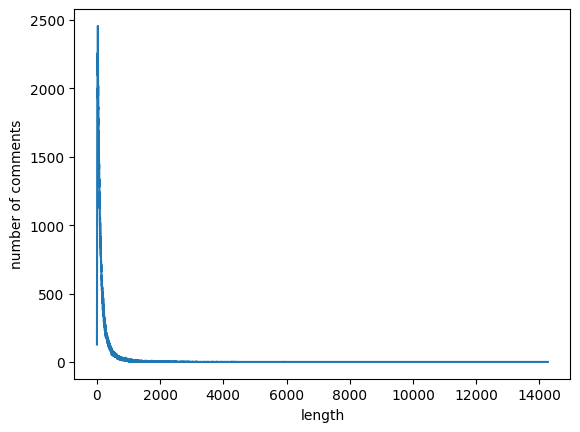

filtered train data


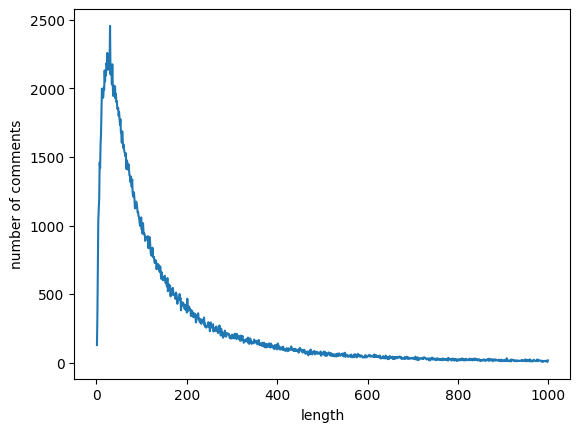

unsupervised data


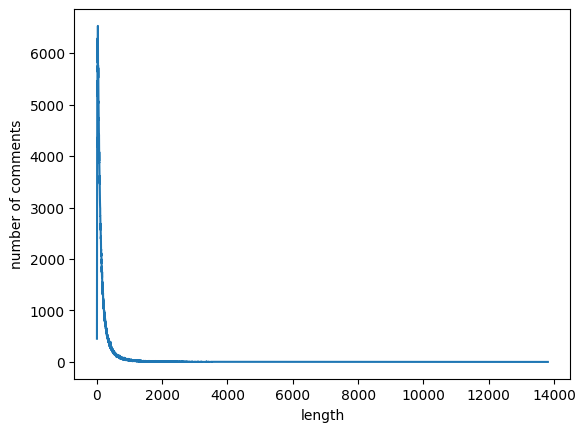

filtered unsupervised data


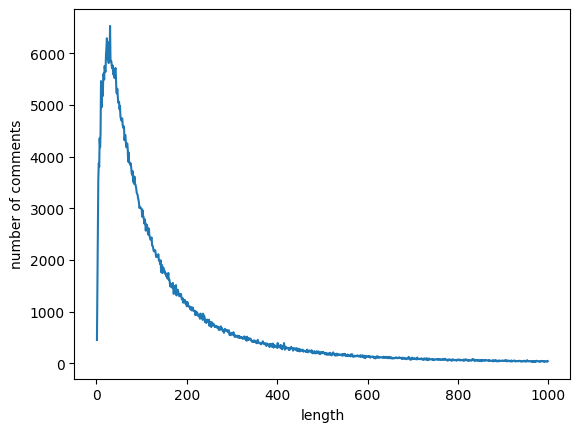

In [54]:
def plotEmpiricalDistributionNumberOfComments(data):

    #we can define a series that has the length as an index and the number of comments that match the length as the value
    countForLenght=data.groupby('length').count()['body']

    #print(countForLenght.max)

    x = countForLenght.index
    y =  countForLenght.values

    df = pd.DataFrame({
        'length' : x, #'length' : x[0:1000], 
        'number of comments' : y#[0:1000]
    })

    plt.figure()
    sns.lineplot(
        data = df, # which dataframe you want to use as the source data
        x = 'length', # which column to use for x-axis
        y = 'number of comments', # which column to use for y-axis
        ax = plt.gca() # assign this plot to current axis, not mandatory in this case
    )
    plt.show()

train_data['length'] = train_data['body'].astype(str).apply(len)
unsupervised_data['length'] = unsupervised_data['body'].astype(str).apply(len)

print("train data")
plotEmpiricalDistributionNumberOfComments(train_data)
print("filtered train data")
plotEmpiricalDistributionNumberOfComments(train_data[train_data['length'] < 1000])
print("unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data)
print("filtered unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data[unsupervised_data['length'] < 1000])


distribution of the number of comments per author

In [7]:
#save DF as csv
unsupervised_data.groupby('author').count().to_csv("number_of_comments_per_author_unsupervised.csv", index=False)

train data author distribution without outliers


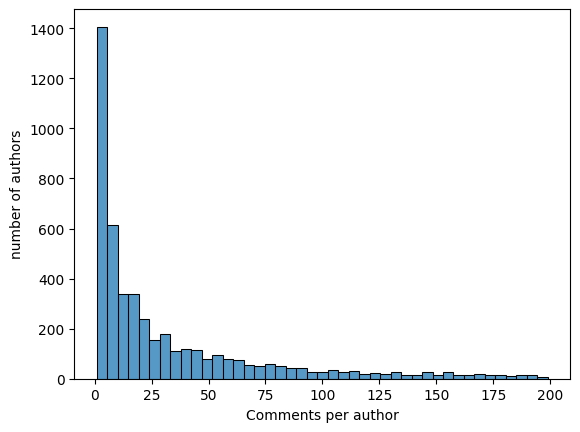

unsupervised data author distribution without outliers


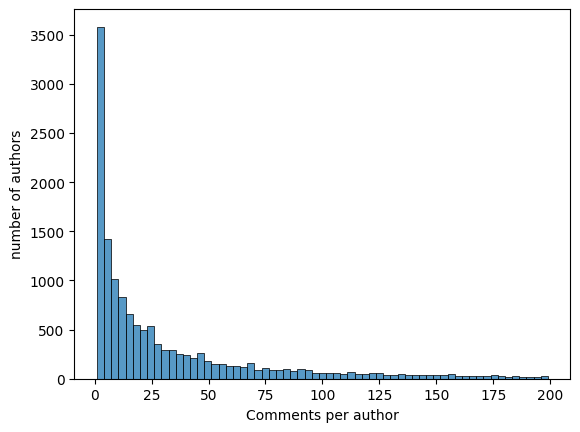

In [14]:
print("train data author distribution without outliers")
plt.figure()
sns.histplot(
    train_data.groupby('author').count()['body'][train_data.groupby('author').count()['body']<200]
)
plt.xlabel("Comments per author")
plt.ylabel("number of authors")
plt.show()

print("unsupervised data author distribution without outliers")
plt.figure()
sns.histplot(
    unsupervised_data.groupby('author').count()['body'][unsupervised_data.groupby('author').count()['body'] < 200]
)
plt.xlabel("Comments per author")
plt.ylabel("number of authors")

plt.show()


        author
gender        
0         3651
1         1349


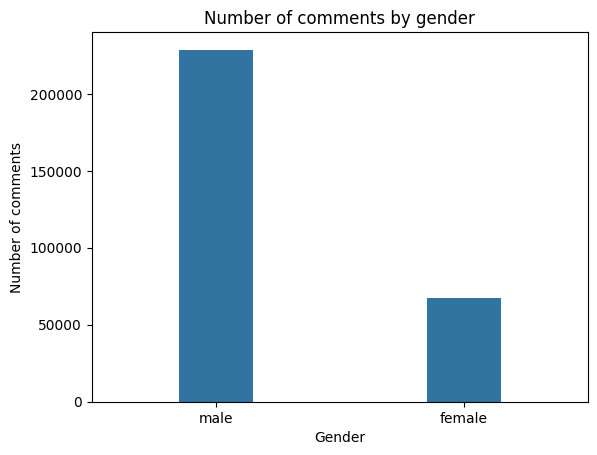

In [23]:
#printing the number of males and females
print(target.groupby('gender').count())

#printing the number of comments for males and females
merged = pd.merge(target, train_data, on='author')

# 2️⃣ Conta il numero di commenti per genere
counts = merged.groupby('gender').count()['body']  # Serie con indice = gender e valori = numero di commenti

# 3️⃣ Trasformo in liste per Seaborn
x_labels = counts.index.tolist()   # [0, 1]
y_values = counts.values.tolist()  # numero di commenti

# 4️⃣ Plot
plt.figure()
sns.barplot(x=["male", "female"], y=y_values, width=0.3)

plt.xlabel("Gender")
plt.ylabel("Number of comments")
plt.title("Number of comments by gender")
plt.show()

ENGLISH COMMENT

language
en       269722
de         2222
af         2043
fr         1968
cy         1720
so         1715
nl         1625
error      1473
tl         1191
da         1187
no         1146
id         1016
it          900
sv          765
pt          750
ro          692
et          685
ca          659
es          635
tr          601
sw          512
pl          508
vi          414
fi          301
sq          279
sl          237
hr          221
sk          196
cs          193
hu          187
lt          123
lv           80
ja           24
kn           20
ko            7
he            5
ru            4
el            3
hi            2
zh-cn         2
th            1
zh-tw         1
Name: count, dtype: int64


C:\Users\giorg\AppData\Local\Temp\ipykernel_14980\2931519435.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette="viridis")


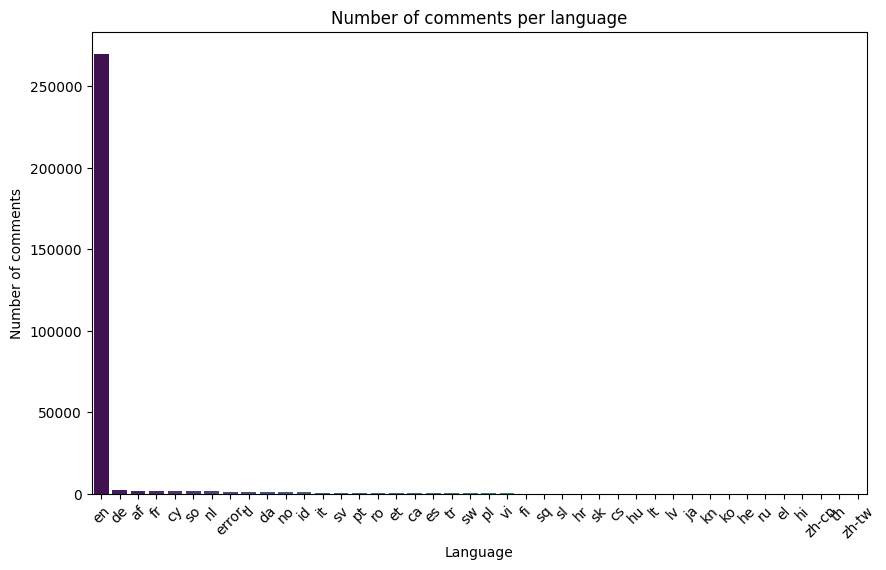

In [5]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0  # rende i risultati stabili
import pandas as pd

# Assicuriamoci che 'body' sia stringa
train_data['body'] = train_data['body'].fillna('').astype(str)

# Applichiamo il rilevamento lingua gestendo errori e testi vuoti
langs = []
for text in train_data['body']:
    if not text.strip():  # se il commento è vuoto
        langs.append("empty")
    else:
        try:
            langs.append(detect(text))
        except:
            langs.append("error")

train_data['language'] = langs

# Conta quante frasi ci sono per ciascuna lingua
counts = train_data['language'].value_counts()
print(counts)

counts = counts.sort_values(ascending=False)

# Grafico
plt.figure(figsize=(10,6))
sns.barplot(x=counts.index, y=counts.values, palette="viridis")

plt.xlabel("Language")
plt.ylabel("Number of comments")
plt.title("Number of comments per language")
plt.xticks(rotation=45)  # ruota le etichette per leggerle meglio
plt.show()



In [6]:
train_data_en = train_data[train_data["language"] == "en"]
print("Forma filtrata (solo inglese, soglia 0.4):", train_data_en.shape)

Forma filtrata (solo inglese, soglia 0.4): (269722, 5)


In [8]:
print(train_data.head(10))
from langdetect import detect_langs
import pandas as pd

# Supponiamo che train_data sia già caricato e contenga la colonna "body"
ambigui = []

for i, commento in enumerate(train_data["body"]):
    try:
        langs = detect_langs(commento)
        best = langs[0]  # lingua con la probabilità più alta
        if best.prob < 0.70:   # soglia di confidenza
            ambigui.append((i, commento[:100], langs))  # salvo i casi incerti
    except:
        ambigui.append((i, commento[:100], "Errore"))

# Mostra i primi 10 casi incerti
print("uncertain cases")
for riga in ambigui[:10]:
    print(riga)

          author          subreddit   created_utc  \
0    Shamus_Aran       mylittlepony  1.388534e+09   
1       Riddance                sex  1.388534e+09   
2  Secret_Wizard       DragonsDogma  1.388534e+09   
3   Penultimatum  malefashionadvice  1.388534e+09   
4      7-SE7EN-7      todayilearned  1.388534e+09   
5        Sahil17       Christianity  1.388534e+09   
6         spyfer      NetflixBestOf  1.388534e+09   
7         tehftw          AskReddit  1.388534e+09   
8      timsstuff             movies  1.388534e+09   
9  Bullseye4hire             hockey  1.388534e+09   

                                                body language  
0  I don't think we'd get nearly as much fanficti...       en  
1  Thanks. I made it up, that's how I got over my...       en  
2  Are you sure you aren't confusing Cyclops (the...       en  
3                             dont do this to me bro       pt  
4        That's what we do when we can't find a mate       en  
5  Damn I love this question. He

In [8]:
from langdetect import detect_langs
import pandas as pd
#dato che i casi ambigui in realtà non lo sono piu di tanto, si detecta la lingua consniderando quella con la probabilità piu alta
def rileva_lingua(testo):
    try:
        langs = detect_langs(testo)
        best = langs[0]  # lingua più probabile
        if best.lang == "en" and best.prob >= 0.4:   # soglia di confidenza
            return "en"
        else:
            return best.lang # troppo dubbio
    except:
        return "error"  # non rilevabile

# Applichiamo il rilevamento lingua alla colonna "body"
train_data["lang"] = train_data["body"].astype(str).apply(rileva_lingua)

# Filtra SOLO righe in inglese
train_data_en = train_data[train_data["lang"] == "en"]

print("Forma iniziale:", train_data.shape)
print("Forma filtrata (solo inglese):", train_data_en.shape)

# Se vuoi sovrascrivere
train_data = train_data_en.reset_index(drop=True)


Forma iniziale: (296035, 5)
Forma filtrata (solo inglese): (269553, 5)


In [44]:
#train_data=train_data.map(lambda x: x.lower() if isinstance(x, str) else x)
#target=target.map(lambda x: x.lower() if isinstance(x, str) else x)
#unsupervised_data=unsupervised_data.map(lambda x: x.lower() if isinstance(x, str) else x)
import re

def clean_text(text):
    text = str(text).lower()
    
    # rimuove URL
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # rimuove riferimenti a subreddit (/r/...)
    text = re.sub(r'/r/\w+', '', text)
    
    # rimuove riferimenti a utenti (/u/...)
    text = re.sub(r'/u/\w+', '', text)
    # numeri
    text = re.sub(r'\d+', '', text)
        
    # punteggiatura
    text = re.sub(r'[^\w\s]', '', text)
    
    # rimuove spazi multipli
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# applica ai dataset
train_data['body'] = train_data['body'].apply(clean_text)
unsupervised_data['body'] = unsupervised_data['body'].apply(clean_text)

codice mio per mostfrequent

In [45]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# --- TRAIN DATA ---
print("TRAIN DATA - FIRST 10 COMMENTS BEFORE:")
print(train_data['body'].head(10).values)

train_data['body'] = train_data['body'].apply(
    lambda x: ' '.join([w for w in x.split() if w not in stop_words])
)

print("\nTRAIN DATA - FIRST 10 COMMENTS AFTER:")
print(train_data['body'].head(10).values)


# --- UNSUPERVISED DATA ---
print("\nUNSUPERVISED DATA - FIRST 10 COMMENTS BEFORE:")
print(unsupervised_data['body'].head(10).values)

unsupervised_data['body'] = unsupervised_data['body'].apply(
    lambda x: ' '.join([w for w in x.split() if w not in stop_words])
)

print("\nUNSUPERVISED DATA - FIRST 10 COMMENTS AFTER:")
print(unsupervised_data['body'].head(10).values)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\giorg\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


TRAIN DATA - FIRST 10 COMMENTS BEFORE:
['i dont think wed get nearly as much fanfiction and pictures shipping banban and lyro just saying'
 'thanks i made it up thats how i got over my first heart break'
 'are you sure you arent confusing cyclops the easiest boss monster for ogres im talking about these guys maybe im just a bad player but every time i faced one on my first playthrough all my pawns ended up getting to hp at least once and i could barely get an attack in once it started berserking'
 'dont do this to me bro' 'thats what we do when we cant find a mate'
 'damn i love this question heres what i think church fathers and earlier heresies ie gnosticism marcionism arianism etc also including arguments church fathers held for the true christianity and itd be awesome if there was st nicholas laying the smack down on arius persecutions of christians constantines conversion and legalization of christianity ecumenical councils charlemagne and some his ancestors such as pepin the shor

In [9]:
#train_data['body'].str.split().explode()

MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)
for word in MostFrequentWords:
    train_data['body']=train_data['body'].str.replace(rf'\b{word}\b', '', regex=True)
MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)


NameError: name 'numberStopwords' is not defined

In [46]:
from nltk.stem import WordNetLemmatizer
print(train_data['body'].head(10).values)
# Function to tokenize and lemmatize a single text
def lemmatize_text(text, lemmatizer):
    tokens = text.split()  # evita word_tokenize (niente punkt)
    
    lemmatized_words = []
    for word in tokens:
        lemmatized_word = lemmatizer.lemmatize(word)
        lemmatized_words.append(lemmatized_word)
    
    lemmatized_text = ' '.join(lemmatized_words)
    return lemmatized_text


def lemmatization(df):
    lemmatizer = WordNetLemmatizer()

    for index, row in df.iterrows():  # CORRETTO: usa df, non train_data
        lemmatized_result = lemmatize_text(row['body'], lemmatizer)
        df.at[index, 'body'] = lemmatized_result

    return df


# applicazione al dataset
train_data = lemmatization(train_data)
    



['dont think wed get nearly much fanfiction pictures shipping banban lyro saying'
 'thanks made thats got first heart break'
 'sure arent confusing cyclops easiest boss monster ogres im talking guys maybe im bad player every time faced one first playthrough pawns ended getting hp least could barely get attack started berserking'
 'dont bro' 'thats cant find mate'
 'damn love question heres think church fathers earlier heresies ie gnosticism marcionism arianism etc also including arguments church fathers held true christianity itd awesome st nicholas laying smack arius persecutions christians constantines conversion legalization christianity ecumenical councils charlemagne ancestors pepin short justinians hagia sophia said something along lines solomon surpassed islam christianislamic tension great schism crusades inquisition great western schism antipopes true popes council constance renaissance popes werent known great martin luther views would differ since catholics orthodox protesta

In [47]:
# Print the resulting DataFrame
print(train_data['body'].head(10).values)
print(train_data.shape)

['dont think wed get nearly much fanfiction picture shipping banban lyro saying'
 'thanks made thats got first heart break'
 'sure arent confusing cyclops easiest bos monster ogre im talking guy maybe im bad player every time faced one first playthrough pawn ended getting hp least could barely get attack started berserking'
 'dont bro' 'thats cant find mate'
 'damn love question here think church father earlier heresy ie gnosticism marcionism arianism etc also including argument church father held true christianity itd awesome st nicholas laying smack arius persecution christian constantine conversion legalization christianity ecumenical council charlemagne ancestor pepin short justinian hagia sophia said something along line solomon surpassed islam christianislamic tension great schism crusade inquisition great western schism antipope true pope council constance renaissance pope werent known great martin luther view would differ since catholic orthodox protestant would disagree king h

In [50]:
# stemming
from nltk.stem import LancasterStemmer

def stemmer_text(text, stemmer):
    # Tokenize the text into words
    # tokens = word_tokenize(text)
    tokens = text.split()  # evitiamo problemi con punkt

    stemmer_words = []
    for word in tokens: 
        stemmer_words.append(stemmer.stem(word))
    
    stemmed_text = ' '.join(stemmer_words)
    return stemmed_text


def stemmization(df):
    stemmer = LancasterStemmer()

    for index, row in df.iterrows():  # FIX: df e non train_data
        stemmed_result = stemmer_text(row['body'], stemmer)
        df.at[index, 'body'] = stemmed_result

    return df


# applicazione
train_data = stemmization(train_data)


In [51]:
print(train_data['body'].head(10).values)

['dont think wed get near much fanfict pict ship banb lyro say'
 'thank mad that got first heart break'
 'sur ar confus cyclop easiest bos monst ogr im talk guy mayb im bad play every tim fac on first playthrough pawn end get hp least could bar get attack start berserk'
 'dont bro' 'that cant find mat'
 'damn lov quest her think church fath ear heresy ie gnost marc ar etc also includ argu church fath held tru christianity itd awesom st nichola lay smack ari persecut christian constantin convert leg christianity ecum council charlemagn ancest pepin short justin hag soph said someth along lin solomon surpass islam christianislamic tend gre schism crusad inquisit gre western schism antipop tru pop council const renaiss pop wer known gre martin luth view would diff sint cathol orthodox protest would disagr king henry vii ris church england council trent cathol bibl napoleon naz fasc commun christian respons mayb gandh vat council ii cathol church sexabus scand also fals teach lik harold ca

In [10]:
#grouping by the author
#TODO controllare se sta roba serve
train_data=train_data[['author','body']].groupby('author').agg(' '.join).reset_index()
print(train_data.head(3))
vectorizerCount = CountVectorizer()
vectorizerCount.fit(train_data['body'])
vectorizerCount = vectorizerCount.transform(train_data['body'])

     author                                               body
0  -evasian  i just received my deathadder black edition ye...
1    -jared  neil diamond - sweet caroline +1 on the chirop...
2   -peeter                         just read the faq, really.


In [16]:
print(vectorizerCount.shape)
#print(csr_matrix(vectorizerCount.toarray()))
#print(len(vectorizerCount.vocabulary_))


(4944, 137483)


In [11]:
vectorizerTfidf = TfidfVectorizer()
vectorizerTfidf.fit(train_data['body'])
#print(sorted(vectorizerTfidf.vocabulary_))
vectorizerTfidf = vectorizerTfidf.transform(train_data['body'])
print(vectorizerTfidf[2])
#vectorizerTfidf.fit(unsupervised_data['body'])
#print(sorted(vectorizerTfidf.vocabulary_))
#vectorizerTfidf = vectorizerTfidf.transform(unsupervised_data['body']))

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5 stored elements and shape (1, 137483)>
  Coords	Values
  (0, 49325)	0.8494306823036974
  (0, 69730)	0.22267455053143276
  (0, 100806)	0.35866820778839553
  (0, 100898)	0.258011512965322
  (0, 120868)	0.1834958757190616


4. Reduce the complexity of your dataset.

In [13]:
#pca=PCA(n_components=PCA_number_components,random_state=42,)
#pca.fit(vectorizerTfidf)

from sklearn.decomposition import TruncatedSVD
import numpy as np

# Supponiamo di avere X_tfidf dal tuo TfidfVectorizer
n_components = 2000  # numero di componenti iniziale

svd = TruncatedSVD(n_components=n_components, random_state=42)
X_reduced = svd.fit_transform(vectorizerCount)

# Calcola la varianza spiegata cumulativa
explained_var = np.sum(svd.explained_variance_ratio_)
print(f"Cumulative explained variance with {n_components} components: {explained_var:.2%}")
import pandas as pd

# Converti l'array numpy in un DataFrame
df_reduced = pd.DataFrame(X_reduced)
#aggiungi la colonna author
df_reduced.insert(0, "author", train_data["author"].values)


# Salva in un file CSV
df_reduced.to_csv("X_reduced_svd.csv", index=True)
print(df_reduced[1])
print("File salvato come X_reduced_svd.csv")



Cumulative explained variance with 2000 components: 99.98%
0      -8.323029
1      -0.378251
2      -0.163695
3      -0.534567
4      -0.241359
          ...   
4939   -1.732167
4940   -6.443540
4941    7.169717
4942    0.305228
4943   -0.520517
Name: 1, Length: 4944, dtype: float64
File salvato come X_reduced_svd.csv


In [14]:

# carico il file con le etichette (deve avere colonne ['author', 'gender'])
df_labels = pd.read_csv("target_supervised.csv")
#puliscom le colonne author
df_reduced['author'] = df_reduced['author'].str.strip().str.lower()
df_labels['author'] = df_labels['author'].str.strip().str.lower()


# unisco sul campo 'author'
df_final = pd.merge(df_reduced, df_labels, on="author", how="inner")

# porto 'gender' in prima colonna
cols = ['gender'] + [c for c in df_final.columns if c != 'gender']
df_final = df_final[cols]

# salvo il dataset pronto
df_final.to_csv("X_reduced_with_labels.csv", index=False)



In [15]:
#df_reduced['author'].duplicated().sum()
df_labels['author'].duplicated().sum()
# autori presenti in X_reduced ma non in labels
missing_in_labels = set(df_reduced['author']) - set(df_labels['author'])
print("Autori mancanti in labels:", missing_in_labels)

# autori presenti in labels ma non in X_reduced
missing_in_reduced = set(df_labels['author']) - set(df_reduced['author'])
print("Autori mancanti in X_reduced:", missing_in_reduced)



Autori mancanti in labels: set()
Autori mancanti in X_reduced: {'wtfwaffles', 'yellieee', 'eodoperative', 'kanpai_slainte', 'msmkat', 'bkling', 'cakewedge', 'gearhead90', 'rickgene', 'spudtastic', 'maniactigris', 'jacked-t', 'kingpanday', 'crankytank', 'plecter', 'poiar', 'ex_temporaneous', 'slendermanx', 'ppity', 'jetersauce', 'slive', 'doctordm', 'aartimus_prime', 'welshcorgis', 'mrmmmmm', 'cywanese', 'blaxk', '_bookworm', 'ss15', 'siim555', 'whygodwhyyy', 'train1231', 'jorikk', 'octahedron8', 'ultimate_ging', 'hellohurricane801', 'krippling', 'lyssalyssalyssa', 'drewnonumber', 'alexoftheyear', 'chanaynay', 'emilyla', 'cloakwandstone', 'redditat-tat', 'sddcsurf', 'sigtrap', 'puddums', 'blueberry_nutsack', 'wxns', 'monkeytoes_', 'baturkey', 'kev92685', 'aafroking', 'bsod666rrod', 'isleepalot', 'neverahappyending342'}


In [1]:
# # describe how much of the dataset variability is indicated by a given amount of features
# explained_variance = pca.explained_variance_ratio_

# # evaluate the total dataset variability while increasing the variables
# cumul_exp_var = np.cumsum(explained_variance)

# # percentage value to better understand the best number of components
# perc_cumul_exp_var = cumul_exp_var * 100

# # make the plot of cumulative explained variance wrt number of components

# plt.figure(figsize=(5, 3.5))
# plt.plot(perc_cumul_exp_var, marker='o')
# plt.xlabel('# Principal Components (PCs)')
# plt.ylabel('Cumulative explained variance [%]')
# plt.xticks([i for i in range(PCA_number_components)], [i for i in range(1,PCA_number_components+1)])
# plt.grid()
# plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')
# plt.tight_layout()
# plt.show()

# print(perc_cumul_exp_var[-1])
# pca_result = pca.transform(vectorizerTfidf)

# dfPCA=pd.DataFrame(pca_result)
# dfPCA.to_csv("PCA.csv")
# print(dfPCA.shape)